# 🔧 Setup

In [25]:
from pipeline import get_feature_names, get_target_name, build_model_pipeline

import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split)

from sklearn.linear_model import (LogisticRegression)

import data_loader
import evaluation 

## TESTING
import importlib

PATH_DATA ='data/raw/Telco_customer_churn.xlsx'
SEED = 4586

In [26]:
generic_colors : list[str] = [ "#0000ff", "#f63400", "#9d02d7", "#ff6ecd", "#9b0000" ]
evaluation.set_color_cycle(generic_colors)


# 📦 Train-Test split

In [27]:
df = data_loader.load_churn_data(PATH_DATA)

In [28]:
X = df[get_feature_names(False)]
y = df[get_target_name(False)]

In [29]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=SEED, stratify=y)
y_test.value_counts()

Churn Value
0    1294
1     467
Name: count, dtype: int64

# 🎯 Métricas alvo
>- **`recall`** >= `0.80` : `recall` é a porcentagem de casos positivos (nesse caso `churn_value = 1`) que o modelo capturou. Um recall 0.80 significa que, de todos os clientes que realmente cancelaram, o modelo identificou corretamente 80%. Um `recall` baixo significa que o modelo não está detectando muitos dos casos positivos.
>- **`precision`** >= `0.5` :  `precision` é a porcentagem de predições positivas que o modelo acertou. Um precision de 0.5 significa que, dos clientes que o modelo apontou como estando em risco, 50% realmente cancelaram (e portanto tem `churn_value = 1`). Um `precision` baixo significa que o modelo está retornando muitos falsos positivos.

Vamos fazer ajustes para chegar o mais perto possível dessas métricas com todos os nossos modelos, inclusive o baseline.
>- **`GridSearchCV`** Testará diferentes parâmetros do modelo para encontrar o que performa melhor, e testará esses parâmetros em fatias diferentes do dataset para checar consistência
>- **`evaluation.get_oof_proba`** Retornará a probabilidade de `churn_value = 1` calculada pelo modelo, assim nos deixando determinar uma probabilidade mínima (`threshold`) em vez de utilizar o default de nossos modelos
>- **`evaluation.plot_roc_pr`** Desenhará gráficos ROC e PR:
>- **`Um gráfico ROC (Receiver Operating Characteristic) curve`** plota `True Positive Rate x False Positive Rate` ao longo de `threshold`. A área em baixo dessa curva (`AUC - Area Under The Curve`) nos diz a qualidade desse modelo, `AUC = 0.5` é um modelo que não performa melhor que simplesmente escolher aleatoriamente, e `1.0` é um modelo perfeito.
>- **`Um gráfico PR (Precision-Recall) curve`** plota `Precision x Recall` ao longo de `threshold`. A `AUC` nos diz a qualidade desse modelo. Sua baseline é a `porcentagem de casos positivos no nosso database` (no nosso caso, ~`0.26`) e `AUC = 1.0` é um modelo perfeito.

# 📝 Baseline
Faremos um modelo simples de LogisticRegression para servir como um baseline aos nossos modelos mais complexos.

In [30]:
model_lr = LogisticRegression()
pipeline_lr = build_model_pipeline(
        model_lr,
        scale=True
    )

models = {
    'lr':pipeline_lr
}

models_grid_params = {
    'lr':{
        'param_grid':{
            'model__solver': ['saga'],
            'model__l1_ratio': [0, 0.25, 0.5, 0.75, 1],  # 0 = pure L2, 1 = pure L1
            'model__C': [0.1, 1.0, 10.0],
            'model__max_iter': [1000],  # Increased so saga converges cleanly
            'model__class_weight':['balanced']
            },
        'scoring':'average_precision'
        }
    }

Com um grid search (`GridSearchCV`), procuraremos os melhores parâmetros para nosso modelo `LogisticRegression`. Utilizaremos essa mesma lógica para a escolha dos modelos de produção depois.

Nosso grid search testa os candidatos em diversas 'fatias' (folds) do dataset, garantindo assim que a performance do modelo não é dependente de overfitting.

In [31]:
grid_results = evaluation.grid_search_models(
    models=models,
    models_grid_params=models_grid_params,
    seed=SEED,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test
    )

In [32]:
evaluation.add_stats_to_grid_results(
    grid_results=grid_results,
    X_train=X_train,
    y_train=y_train,
    y_test=y_test,
    target_recall=0.8,
    seed=SEED)

In [33]:
# importlib.reload(evaluation)
evaluation.display_grid_results(grid_results)

RESULTS FOR "lr"
Best Parameters: {'model__C': 10.0, 'model__class_weight': 'balanced', 'model__l1_ratio': 0, 'model__max_iter': 1000, 'model__solver': 'saga'}
Best CV average_precision: 0.6731
Threshold ( Recall on Test = 0.80 | Precision on Test = 0.54 ) = 0.50


Com os resultados do modelo escolhido, vamos plotar as curvas ROC e PR.

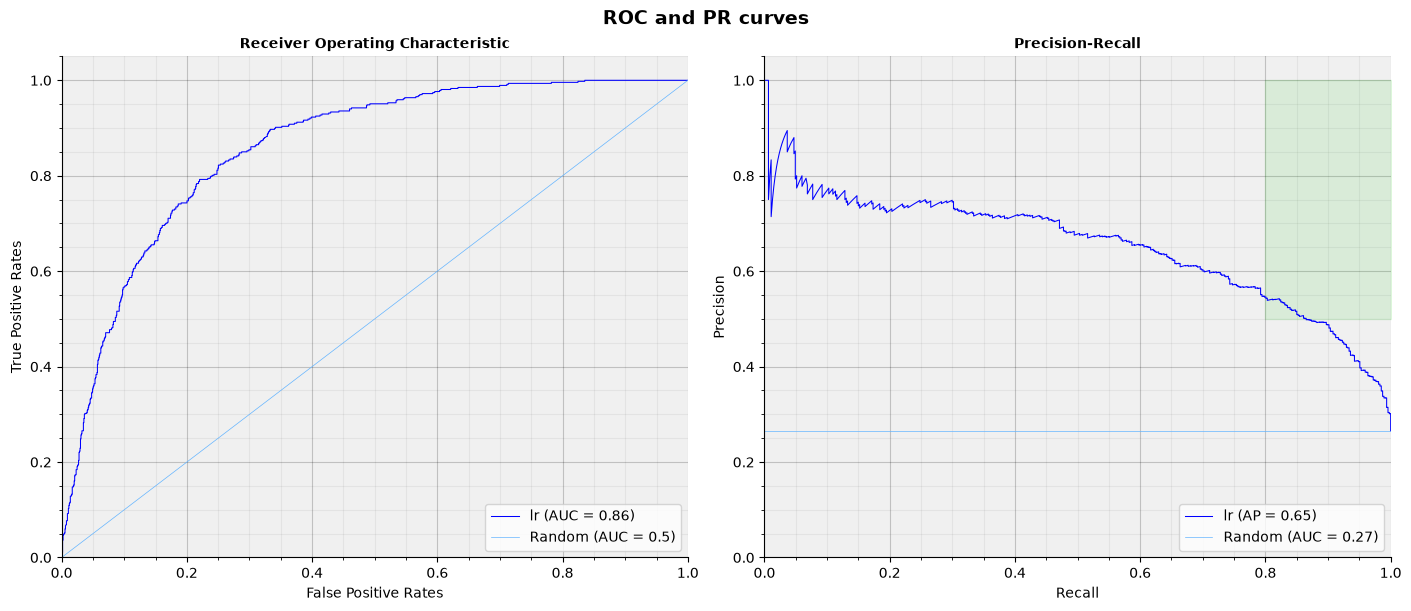

In [34]:
evaluation.plot_multiple_roc_pr(
    y_true=y_test,
    results=grid_results,
    target_recall=0.8,
    min_precision=0.5,
    figsize=(14,6)
)

plt.show()

O modelo obteve uma performance mediana, melhor que a aleatoriedade em AUC-ROC e AUC-PR mas com um precision baixo.

In [35]:
model_baseline = grid_results['lr']['grid_search'].best_estimator_
model_baseline.fit(X_train, y_train)
y_proba = model_baseline.predict_proba(X_test)[:, 1]

In [36]:
evaluation.quick_evaluation(y_test, y_proba, grid_results['lr']['stats']['threshold'])

EVALUATION AT THRESHOLD 0.4981689319781663
              precision    recall  f1-score   support

           0       0.91      0.76      0.83      1294
           1       0.54      0.80      0.65       467

    accuracy                           0.77      1761
   macro avg       0.73      0.78      0.74      1761
weighted avg       0.82      0.77      0.78      1761

acc			0.77
recall			0.80
precision		0.54
f1-score		0.65
average precision	0.65


Nosso modelo baseline `LogisticRegression` obteve:
>- **`accuracy`** = 0.77
>- **`recall`** = 0.80
>- **`precision`** = 0.54
>- **`f1-score`** = 0.65
>- **`average precision`** = 0.65